<center><h1>Last_First_HW4</h1></center>
<br>
<br>

**Name:** Alyssa Keehan 

**GitHub Username:** akeehan56

**GitHub Links:** [Class Repo](https://github.com/akeehan56/DSCI552) | [HW4](https://github.com/akeehan56/DSCI552/tree/main/HW4)

**Email:** akeehan@usc.edu  

**USC ID:** 3429542433

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [34]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Get the AReM Data Set

In [18]:
data_dir = Path("../data/AReM")

activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

### (b) Splitting Data

In [19]:
# split each of the data sets into
test_dataset_numbers = {
    "bending1": [1, 2],
    "bending2": [1, 2],
    "cycling": [1, 2, 3],
    "lying": [1, 2, 3],
    "sitting": [1, 2, 3],
    "standing": [1, 2, 3],
    "walking": [1, 2, 3]
}

In [20]:
train_instances = []
test_instances = []

for activity in activities:
    folder_path = data_dir / activity

    # Find and sort all csv files in the activity folder
    files = sorted(
        folder_path.glob("dataset*.csv"),
        key=lambda file: int(file.stem.replace("dataset", ""))
    )

    for file_path in files:
        dataset_num = int(file_path.stem.replace("dataset", ""))

        # only the first seven columns are retained
        df = pd.read_csv(
            file_path,
            skiprows=5,
            header=None,
            names=columns,
            sep=r"[,\s]+",
            engine="python",
            usecols=range(7)
        )

        # ensure that all values are numeric
        df = df.apply(pd.to_numeric, errors="raise")

        instance = {
            "activity": activity,
            "dataset": dataset_num,
            "file": file_path.name,
            "data": df
        }

        if dataset_num in test_dataset_numbers[activity]:
            test_instances.append(instance)
        else:
            train_instances.append(instance)

In [21]:
print("Training instances:", len(train_instances))
print("Testing instances:", len(test_instances))
print("Total instances:", len(train_instances) + len(test_instances))

Training instances: 69
Testing instances: 19
Total instances: 88


### (c) Feature Extraction

In [22]:
# give each activity an order number for sorting
activity_order = {
    activity: index
    for index, activity in enumerate(activities)
}

# combine the training and testing instances and sort them by activity and dataset number
all_instances = sorted(
    train_instances + test_instances,
    key=lambda instance: (
        activity_order[instance["activity"]],
        instance["dataset"]
    )
)

print("Number of instances:", len(all_instances))

Number of instances: 88


In [23]:
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

# holds the extracted features for each instance
feature_rows = []
# holds the names of the extracted features
feature_columns = []

for instance_number, instance in enumerate(all_instances, start=1):
    row = {
        "Instance": instance_number,
        "Activity": instance["activity"],
        "Dataset": instance["dataset"]
    }

    if instance["dataset"] in test_dataset_numbers[instance["activity"]]:
        row["Split"] = "test"
    else:
        row["Split"] = "train"

    for series_number, column in enumerate(time_series_columns, start=1):
        values = instance["data"][column]

        row[f"min{series_number}"] = values.min()
        row[f"max{series_number}"] = values.max()
        row[f"mean{series_number}"] = values.mean()
        row[f"median{series_number}"] = values.median()
        row[f"std{series_number}"] = values.std(ddof=1)
        row[f"1stQuart{series_number}"] = values.quantile(0.25)
        row[f"3rdQuart{series_number}"] = values.quantile(0.75)

        if instance_number == 1:
            feature_columns.extend([
                f"min{series_number}",
                f"max{series_number}",
                f"mean{series_number}",
                f"median{series_number}",
                f"std{series_number}",
                f"1stQuart{series_number}",
                f"3rdQuart{series_number}"
            ])

    feature_rows.append(row)

feature_dataset = pd.DataFrame(feature_rows)

feature_dataset = feature_dataset[
    ["Instance", "Activity", "Dataset", "Split"] + feature_columns
]

feature_dataset

,Instance,Activity,Dataset,Split,min1,max1,mean1,median1,std1,1stQuart1,...,std5,1stQuart5,3rdQuart5,min6,max6,mean6,median6,std6,1stQuart6,3rdQuart6
0,1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,walking,11,train,19.50,45.33,33.586875,34.25,4.650935,30.25,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,walking,12,train,19.75,45.50,34.322750,35.25,4.752477,31.00,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,86,walking,13,train,19.50,46.00,34.546229,35.25,4.842294,31.25,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,walking,14,train,23.50,46.25,34.873229,35.25,4.531720,31.75,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


In [24]:
print("Dataset shape:", feature_dataset.shape)
print("Number of extracted features:", len(feature_columns))

print(
    "Missing feature values:",
    feature_dataset[feature_columns].isna().sum().sum()
)

Dataset shape: (88, 46)
Number of extracted features: 42
Missing feature values: 0


In [25]:
feature_values = feature_dataset[feature_columns]

std_estimates = feature_values.std(axis=0, ddof=1)

std_estimates

min1         9.569975
max1         4.394362
mean1        5.335718
median1      5.440054
std1         1.772153
1stQuart1    6.153590
3rdQuart1    5.138925
min2         0.000000
max2         5.062729
mean2        1.574164
median2      1.412244
std2         0.884105
1stQuart2    0.946386
3rdQuart2    2.125266
min3         2.956462
max3         4.875137
mean3        4.008380
median3      4.036396
std3         0.946710
1stQuart3    4.220658
3rdQuart3    4.171628
min4         0.000000
max4         2.183625
mean4        1.166114
median4      1.145586
std4         0.458242
1stQuart4    0.843620
3rdQuart4    1.552504
min5         6.124001
max5         5.741238
mean5        5.675593
median5      5.813782
std5         1.024898
1stQuart5    6.096465
3rdQuart5    5.531720
min6         0.045838
max6         2.518921
mean6        1.154812
median6      1.086474
std6         0.517617
1stQuart6    0.758584
3rdQuart6    1.523599
dtype: float64

In [26]:
rng = np.random.default_rng(42)

n_bootstrap = 10000
n_instances = len(feature_values)
n_features = len(feature_columns)

bootstrap_std = np.empty((n_bootstrap, n_features))

feature_array = feature_values.to_numpy()

# randomly sample instances with replacement and compute the standard deviation for each feature
for bootstrap_number in range(n_bootstrap):
    sampled_indices = rng.integers(
        low=0,
        high=n_instances,
        size=n_instances
    )

    bootstrap_sample = feature_array[sampled_indices]

    bootstrap_std[bootstrap_number] = np.std(
        bootstrap_sample,
        axis=0,
        ddof=1
    )

ci_lower = np.percentile(bootstrap_std, 5, axis=0)
ci_upper = np.percentile(bootstrap_std, 95, axis=0)

bootstrap_results = pd.DataFrame({
    "Feature": feature_columns,
    "Standard Deviation": std_estimates.values,
    "90% CI Lower": ci_lower,
    "90% CI Upper": ci_upper
})

bootstrap_results.round(3)

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.570,8.236,10.774
1,max1,4.394,3.340,5.293
2,mean1,5.336,4.704,5.876
3,median1,5.440,4.784,6.006
4,std1,1.772,1.569,1.950
5,1stQuart1,6.154,5.574,6.649
6,3rdQuart1,5.139,4.339,5.834
7,min2,0.000,0.000,0.000
8,max2,5.063,4.631,5.401
9,mean2,1.574,1.396,1.706


In [27]:
selected_features = [
    column
    for column in feature_columns
    if column.startswith(("min", "mean", "max"))
]

selected_features

['min1',
 'max1',
 'mean1',
 'min2',
 'max2',
 'mean2',
 'min3',
 'max3',
 'mean3',
 'min4',
 'max4',
 'mean4',
 'min5',
 'max5',
 'mean5',
 'min6',
 'max6',
 'mean6']

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [30]:
selected_statistics = ["min", "mean", "max"]
selected_series = [1, 2, 6]

def extract_selected_features(instances, n_parts=1):
    rows = []

    for instance in instances:
        activity = instance["activity"]

        row = {
            "activity": activity,
            "dataset": instance["dataset"],
            "class": (
                "Bending"
                if activity in ["bending1", "bending2"]
                else "Other"
            )
        }

        # Split consecutive rows so all six series remain aligned.
        parts = np.array_split(
            np.arange(len(instance["data"])),
            n_parts
        )

        for part_number, indices in enumerate(parts, start=1):
            segment = instance["data"].iloc[indices]

            for series_number, column in enumerate(
                time_series_columns, start=1
            ):
                values = segment[column]

                for feature in selected_statistics:
                    name = f"{feature}{series_number}"

                    if n_parts > 1:
                        name += f"_part{part_number}"

                    row[name] = values.agg(feature)

        rows.append(row)

    return pd.DataFrame(rows)

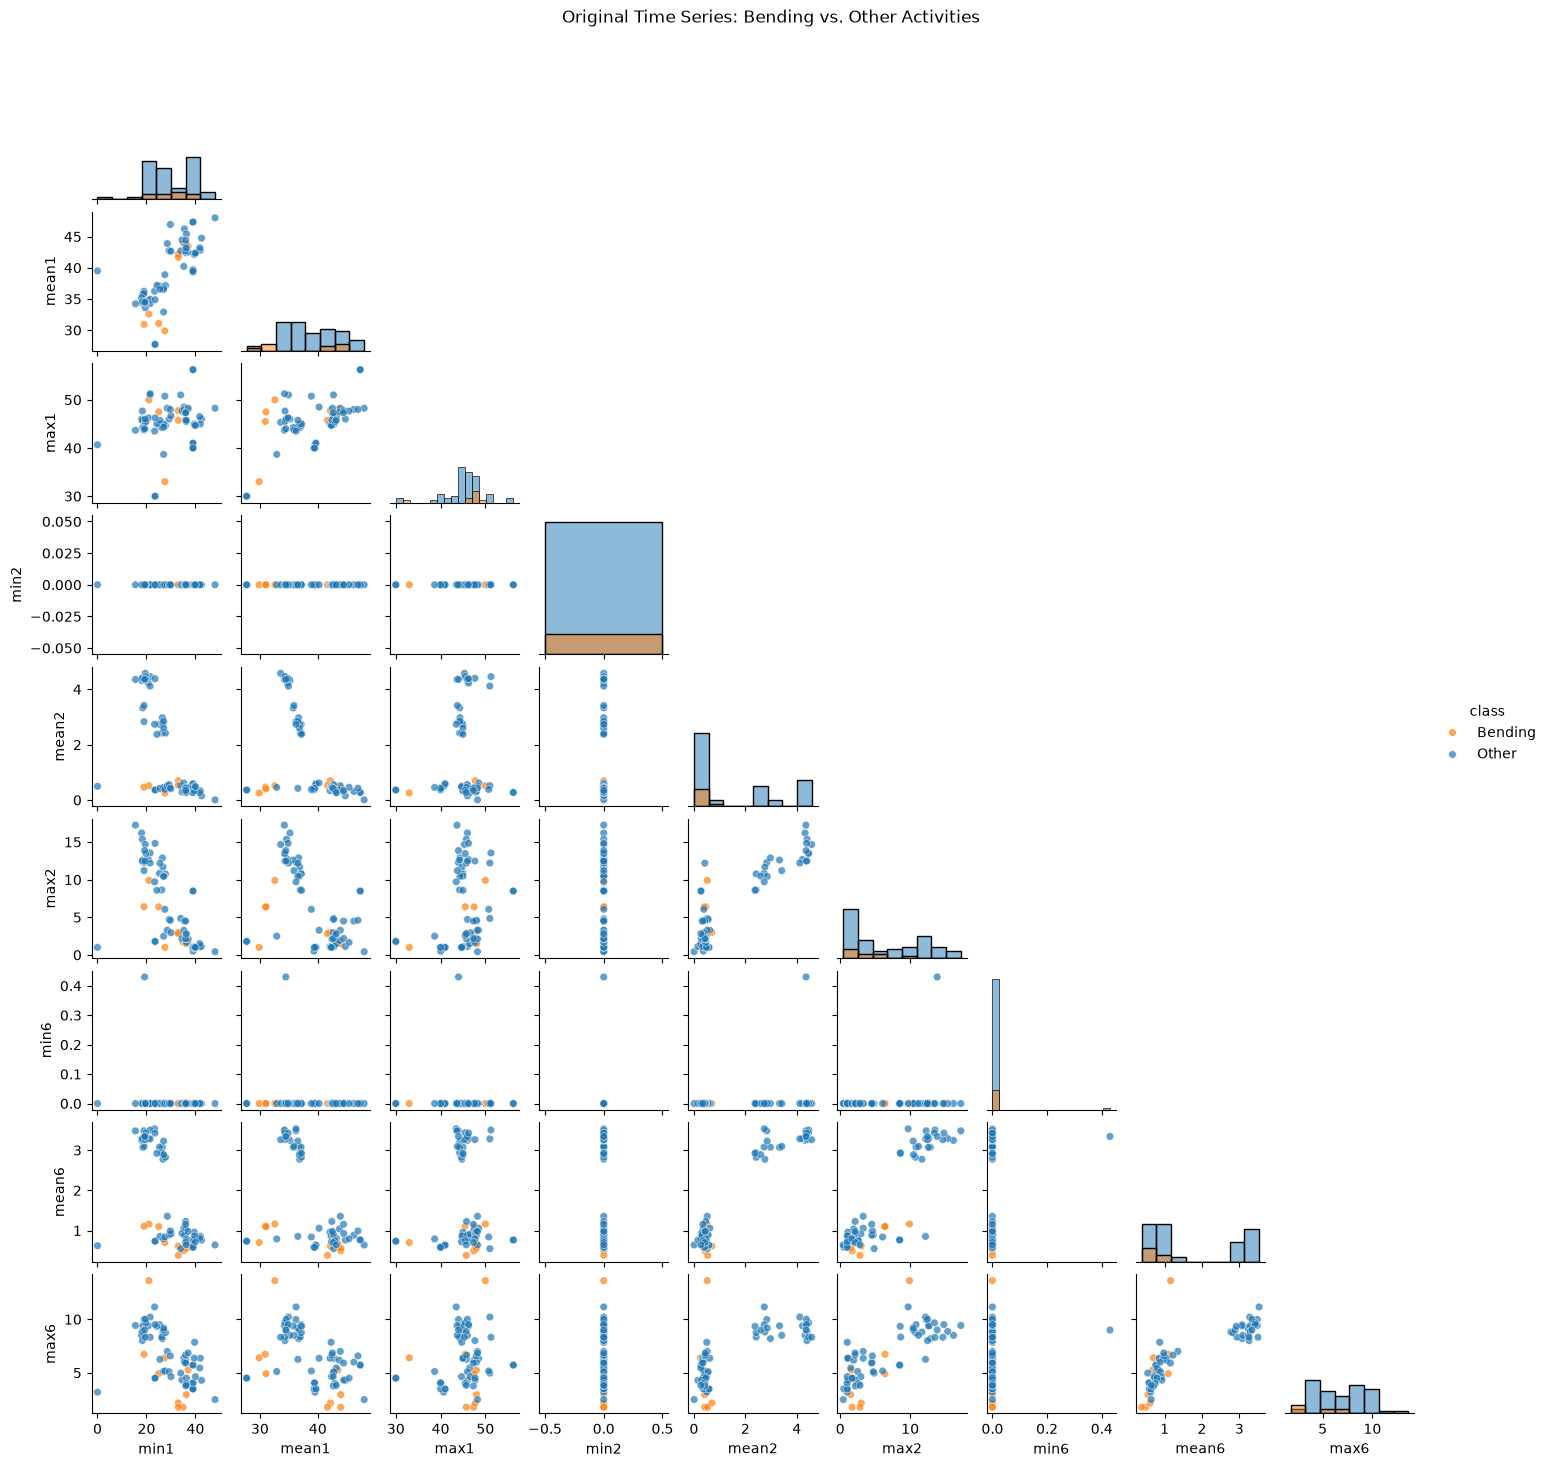

In [31]:
# Extract features from the original training instances.
train_features_original = extract_selected_features(
    train_instances,
    n_parts=1
)

plot_columns_original = [
    f"{feature}{series_number}"
    for series_number in selected_series
    for feature in selected_statistics
]

palette = {
    "Bending": "tab:orange",
    "Other": "tab:blue"
}

g = sns.pairplot(
    data=train_features_original,
    vars=plot_columns_original,
    hue="class",
    hue_order=["Bending", "Other"],
    palette=palette,
    diag_kind="hist",
    corner=True,
    height=1.6,
    plot_kws={"alpha": 0.7, "s": 30}
)

g.fig.suptitle(
    "Original Time Series: Bending vs. Other Activities",
    y=1.02
)

plt.show()

#### ii. Splitted Plots

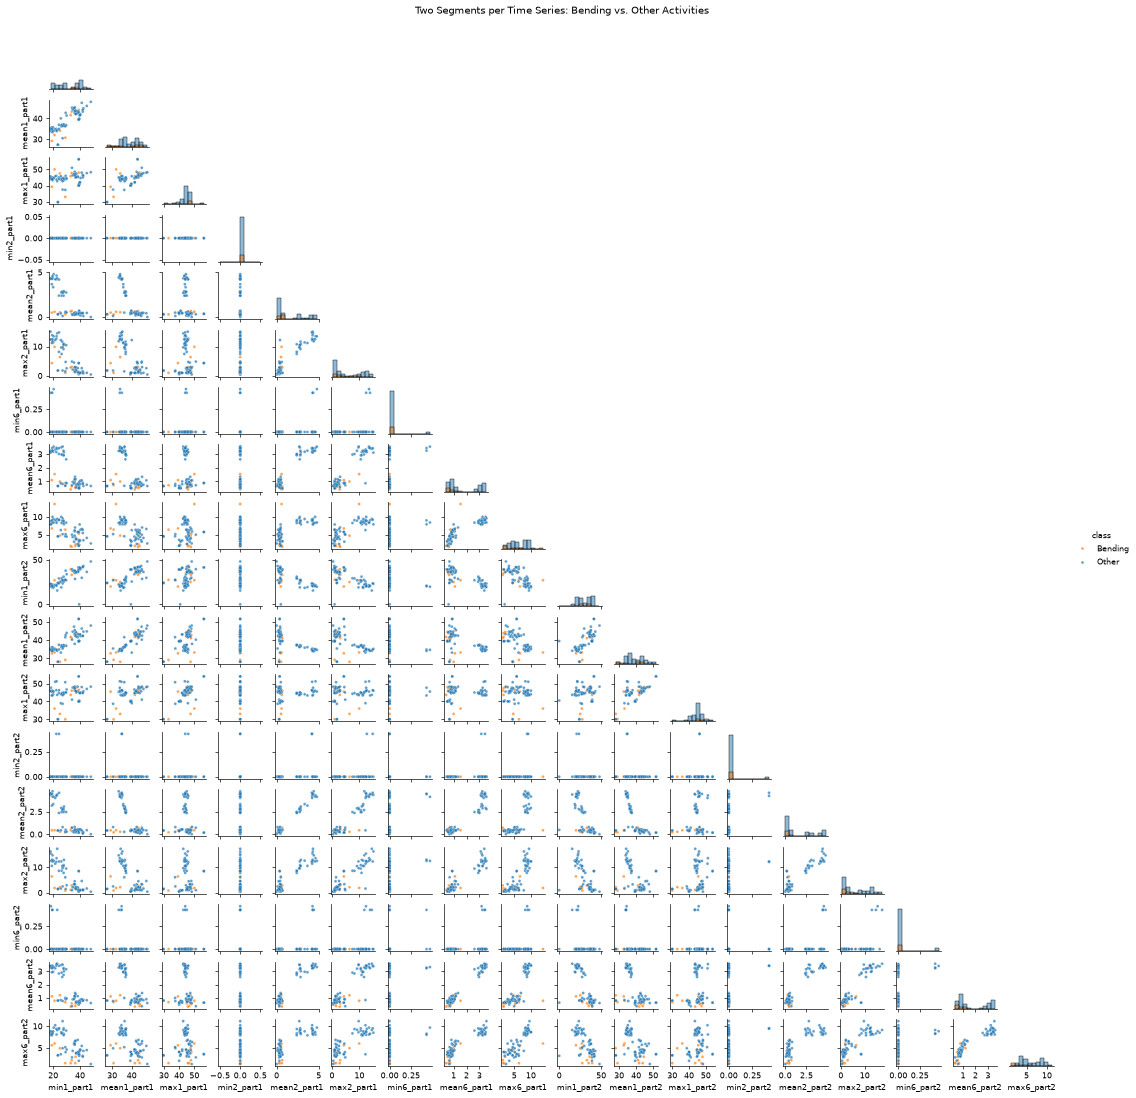

In [33]:
# Close any partially created figures.
plt.close("all")

selected_statistics = ["min", "mean", "max"]
selected_series = [1, 2, 6]

train_features_split = extract_selected_features(
    train_instances,
    n_parts=2
)

plot_columns_split = [
    f"{feature}{series_number}_part{part_number}"
    for part_number in [1, 2]
    for series_number in selected_series
    for feature in selected_statistics
]

# Check column names before creating the large figure.
missing = [
    column for column in plot_columns_split
    if column not in train_features_split.columns
]

if missing:
    raise ValueError(f"Missing feature columns: {missing}")

g = sns.pairplot(
    data=train_features_split,
    vars=plot_columns_split,
    hue="class",
    hue_order=["Bending", "Other"],
    palette=palette,
    diag_kind="hist",
    corner=True,
    height=1.0,
    plot_kws={"alpha": 0.7, "s": 12},
    diag_kws={"bins": 10}
)

g.fig.suptitle(
    "Two Segments per Time Series: Bending vs. Other Activities",
    y=1.02
)

g.fig.set_dpi(60)
plt.show()

**Answer:**
There is no considerable difference in class separation after splitting the time series. Some feature values change, but bending and other activities still overlap in many plots. Therefore, splitting does not appear to substantially improve visual separation.

#### iii. Time Series Segments

##### 1. Define extract egment features function to extract any number of segments

In [35]:
def extract_segment_features(instances, l):
    rows = []

    for instance in instances:
        data = instance["data"]
        row = {}

        # Consecutive, approximately equal-length segments.
        segments = np.array_split(np.arange(len(data)), l)

        for part_number, indices in enumerate(segments, start=1):
            segment = data.iloc[indices]

            for series_number, column in enumerate(
                time_series_columns, start=1
            ):
                values = segment[column]

                statistics = {
                    "min": values.min(),
                    "max": values.max(),
                    "mean": values.mean(),
                    "median": values.median(),
                    "std": values.std(ddof=1),
                    "q1": values.quantile(0.25),
                    "q3": values.quantile(0.75)
                }

                for statistic, value in statistics.items():
                    name = (
                        f"{statistic}{series_number}"
                        f"_part{part_number}"
                    )
                    row[name] = value

        rows.append(row)

    return pd.DataFrame(rows)


# Bending = 1; all other activities = 0.
y_train = np.array([
    int(instance["activity"] in ["bending1", "bending2"])
    for instance in train_instances
])

print("Training instances:", len(y_train))
print("Bending instances:", y_train.sum())
print("Other instances:", (y_train == 0).sum())

Training instances: 69
Bending instances: 9
Other instances: 60


##### 2. Search for the best ($l$, $p$)

In [36]:
# Reuse the same folds for every value of l.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(cv.split(np.zeros(len(y_train)), y_train))

results = []
all_cv_results = []
best_model = None
best_X_train = None
best_key = None

for l in range(1, 21):
    X_train_l = extract_segment_features(train_instances, l)

    estimator = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ])

    selector = RFECV(
        estimator=estimator,
        step=1,
        min_features_to_select=1,
        cv=cv_splits,
        scoring="accuracy",
        importance_getter="named_steps.logistic.coef_",
        n_jobs=-1
    )

    print(
        f"Starting l={l}: {X_train_l.shape[1]} candidate features",
        flush=True
    )

    selector.fit(X_train_l, y_train)

    scores = selector.cv_results_["mean_test_score"]

    # With step=1, scores correspond to p=1, 2, ..., 42*l.
    p_values = np.arange(1, X_train_l.shape[1] + 1)

    all_cv_results.append(pd.DataFrame({
        "l": l,
        "p": p_values,
        "cv_accuracy": scores
    }))

    p = int(selector.n_features_)
    score = float(scores[p - 1])

    results.append({
        "l": l,
        "candidate_features": X_train_l.shape[1],
        "p": p,
        "cv_accuracy": score,
        "cv_error": 1 - score
    })

    # Prefer fewer features, then smaller l, if scores tie.
    key = (score, -p, -l)

    if best_key is None or key > best_key:
        best_key = key
        best_model = selector
        best_X_train = X_train_l
        best_l = l
        best_p = p
        best_cv_accuracy = score

    print(
        f"Finished l={l}: p={p}, CV accuracy={score:.4f}",
        flush=True
    )

results_df = pd.DataFrame(results)
cv_results_df = pd.concat(all_cv_results, ignore_index=True)

display(results_df)

print(f"\nBest (l, p): ({best_l}, {best_p})")
print(f"Mean CV accuracy: {best_cv_accuracy:.4f}")
print(f"Mean CV error: {1 - best_cv_accuracy:.4f}")

best_feature_names = best_X_train.columns[
    best_model.support_
].tolist()

print("\nSelected features:")
print(best_feature_names)

Starting l=1: 42 candidate features
Finished l=1: p=29, CV accuracy=0.9857
Starting l=2: 84 candidate features
Finished l=2: p=12, CV accuracy=0.9714
Starting l=3: 126 candidate features
Finished l=3: p=2, CV accuracy=0.9714
Starting l=4: 168 candidate features
Finished l=4: p=2, CV accuracy=0.9714
Starting l=5: 210 candidate features
Finished l=5: p=11, CV accuracy=0.9714
Starting l=6: 252 candidate features
Finished l=6: p=2, CV accuracy=0.9714
Starting l=7: 294 candidate features
Finished l=7: p=13, CV accuracy=0.9571
Starting l=8: 336 candidate features
Finished l=8: p=1, CV accuracy=0.9429
Starting l=9: 378 candidate features
Finished l=9: p=1, CV accuracy=0.9429
Starting l=10: 420 candidate features
Finished l=10: p=5, CV accuracy=0.9714
Starting l=11: 462 candidate features
Finished l=11: p=2, CV accuracy=0.9714
Starting l=12: 504 candidate features
Finished l=12: p=1, CV accuracy=0.9714
Starting l=13: 546 candidate features
Finished l=13: p=1, CV accuracy=0.9714
Starting l=14: 

,l,candidate_features,p,cv_accuracy,cv_error
0,1,42,29,0.985714,0.014286
1,2,84,12,0.971429,0.028571
2,3,126,2,0.971429,0.028571
3,4,168,2,0.971429,0.028571
4,5,210,11,0.971429,0.028571
5,6,252,2,0.971429,0.028571
6,7,294,13,0.957143,0.042857
7,8,336,1,0.942857,0.057143
8,9,378,1,0.942857,0.057143
9,10,420,5,0.971429,0.028571



Best (l, p): (20, 6)
Mean CV accuracy: 0.9857
Mean CV error: 0.0143

Selected features:
['min5_part3', 'mean5_part3', 'q15_part3', 'q31_part12', 'q14_part15', 'min5_part18']


**Answer:** I used recursive feature elimination with 5-fold stratified cross-validation to select ($l$,$p$). Both ($1$,$29$) and ($20$,$6$) achieved the highest mean validation accuracy of 98.57%. I selected ($20$,$6$) because it uses fewer features. Thus, each original series was divided into 20 segments, and 6 of the 840 candidate features were retained.
Stratification preserved approximately the same class proportions in each fold. Scaling and feature selection were performed within each training fold to avoid leaking validation information. Selecting features before cross-validation would incorrectly allow validation observations to influence the model.

#### iv. Confusion Matrix

#### v. Test Classifier

#### vi. Separation

#### vii. Imbalance

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

## 4. ISLR 4.8.7

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9